In [1]:
%load_ext autoreload
%autoreload 2

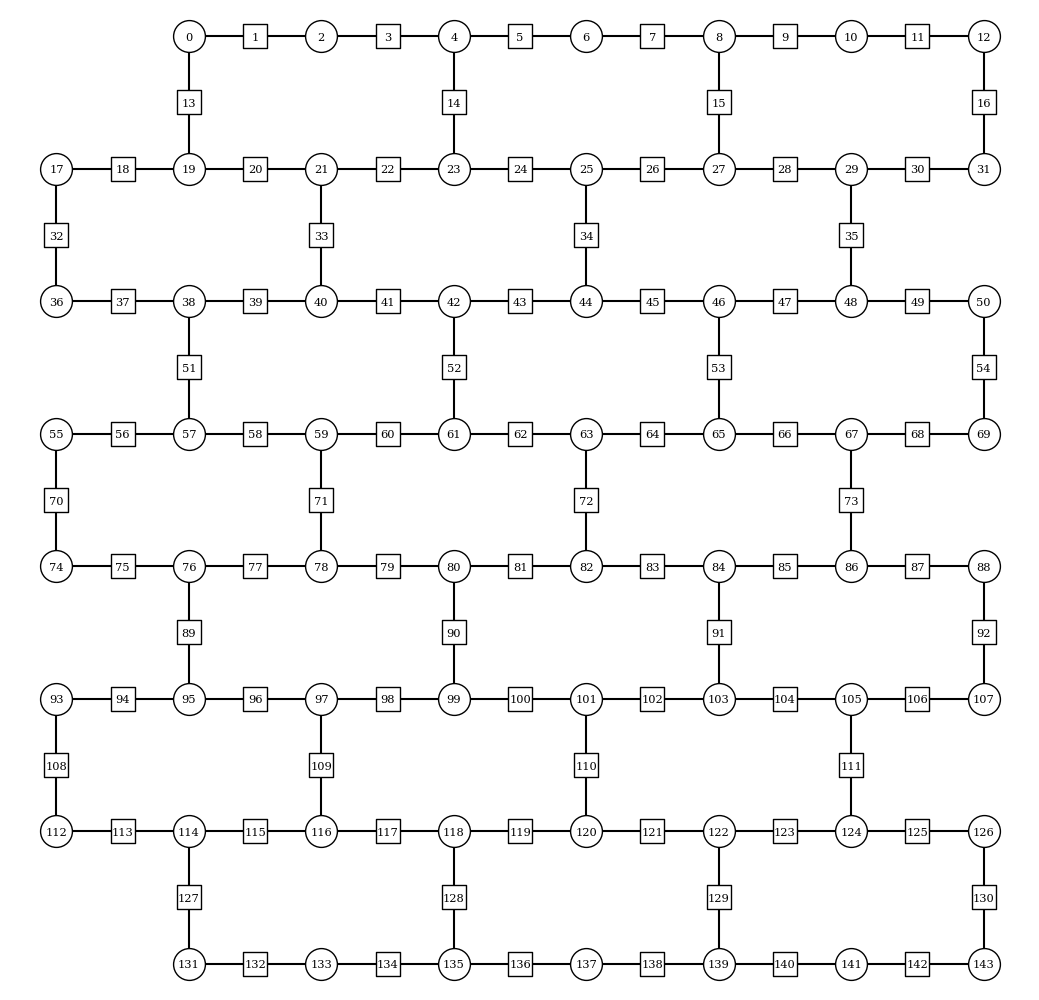

In [2]:
from z2hex.geometry import HeavyHexLattice
 
plaquette_width = 3
plaquette_height = 7

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

In [3]:
og_data_filepth = "1D Data/2nd run close/m_5_g_0.8_clifford.pkl"
new_data_filepath = "1D Data/2nd run close/m_5_g_0.8_clifford_nonan.pkl"

In [4]:
from utils.postselection_multithreaded import load_postselected_jobs_obs_samples
# from z2hex.operators import local_pauli_z, postselection_operators
from z2chain.operators import local_pauli_z, postselection_operators
import numpy as np
import pickle

recovery = True
flip_threshold = 1
minimum_shots = 20000
confidence = 0.7
max_shots = 100000

# Load the old data
with open(og_data_filepth, "rb") as f:
    data = pickle.load(f)
    old_samples = data[2]
    layouts = data[-1]

# Process data
# observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
# postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)
L = 21
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, False)

odr_expected_observable = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, 1, -1, 1, -1, 1, -1, 1, -1, 1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

observables, observables_confidence, samples_dicts, postselected_samples_dicts = load_postselected_jobs_obs_samples(old_samples, postselection_operators_func, observable_generating_funcs, recovery=True, flip_threshold=flip_threshold, minimum_shots=minimum_shots, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, postselect_odr=True, max_shots=max_shots, odr_expected_observable=odr_expected_observable, verbose=True)

# Save the data
with open(new_data_filepath, "wb") as f:
    pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)

Loaded 41 jobs                                                                                     


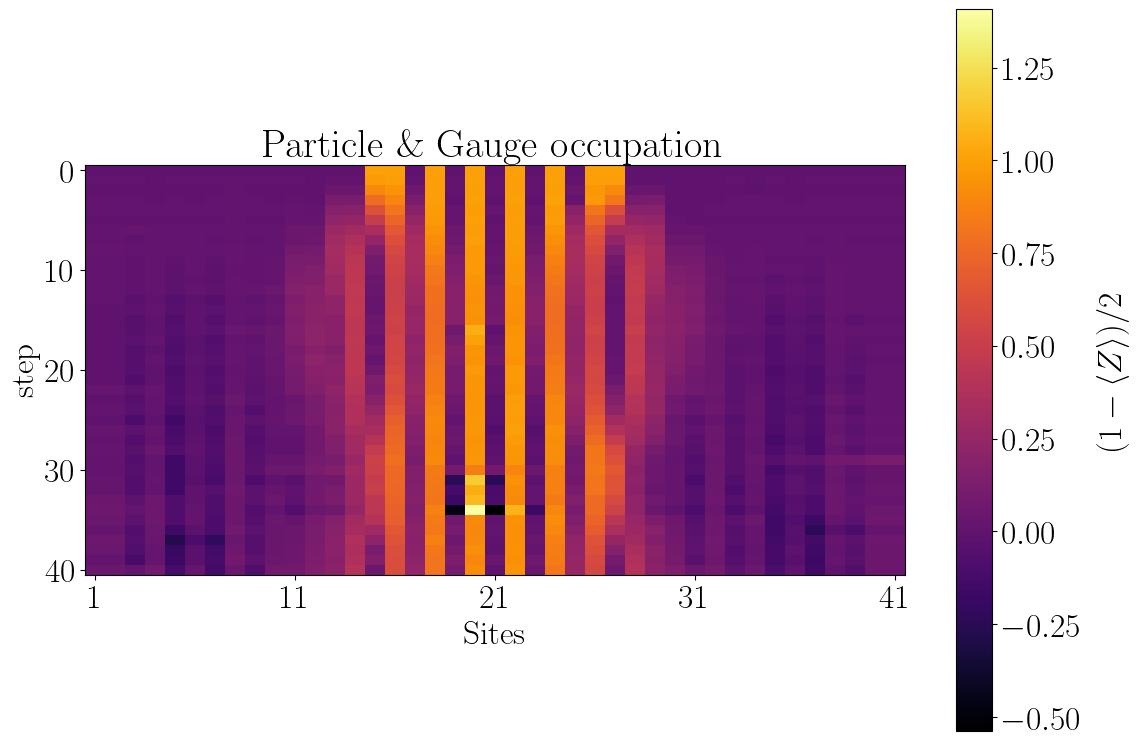

In [6]:
from z2chain.plotting import x_t_plot

x_t_plot((1-observables[0])/2)

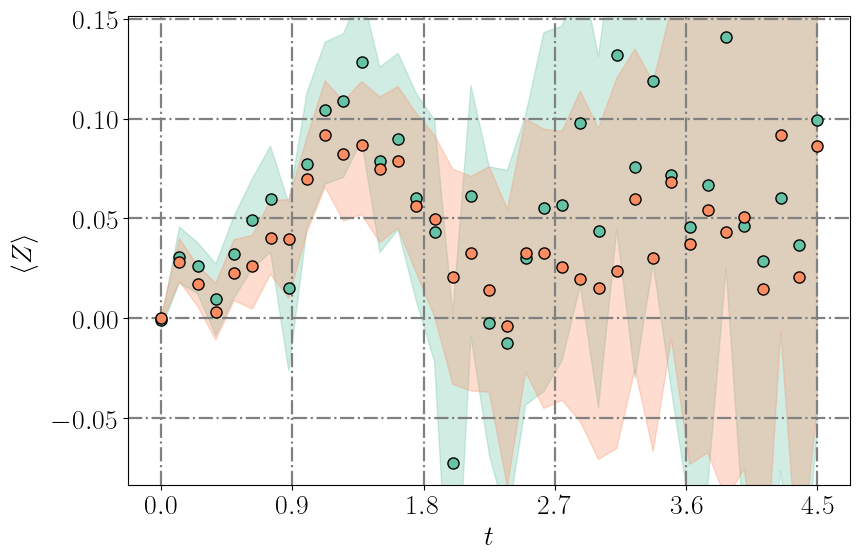

In [24]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

final_time = 4.5
qubits = [8, 59]

# qubits = [14]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = None #f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

# plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
# legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1-observables[0][:, qubits])/2
observables_stdm = (1-observables_confidence[0][:, qubits])/2

# to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--")
# lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)